In [1]:
import sys, numpy, pandas, sklearn, pgmpy
print(sys.executable)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("sklearn:", sklearn.__version__)
print("pgmpy:", pgmpy.__version__)

from pgmpy.inference import VariableElimination, ApproxInference
print("pgmpy inference imported OK")

import tensorflow as tf
print("tensorflow:", tf.__version__)

import matplotlib
print("matplotlib:", matplotlib.__version__)

from imblearn.over_sampling import SMOTE
print("imblearn imported OK")

print("\nALL IMPORTS SUCCEEDED")

C:\Users\devin\anaconda3\envs\faultdiag_new\python.exe
numpy: 2.4.6
pandas: 3.0.6
sklearn: 1.9.1
pgmpy: 1.1.2


C:\Users\devin\anaconda3\envs\faultdiag_new\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\devin\anaconda3\envs\faultdiag_new\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


pgmpy inference imported OK
tensorflow: 2.21.0
matplotlib: 3.11.2
imblearn imported OK

ALL IMPORTS SUCCEEDED


Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.


Note: you may need to restart the kernel to use updated packages.
PHASE 1: DATASET GENERATION
Generated dataset: (48050, 11)
Failure_Type
Normal              35473
Electrical Fault     3759
Overheating          3417
Vibration Issue      3384
Pressure Drop        2017
Name: count, dtype: int64

PHASE 2: DATA PREPROCESSING
Missing values before cleaning:
 Machine_ID                  0
Timestamp                   0
Temperature                 0
Vibration                   0
Humidity                   96
Pressure                    0
Energy_Consumption          0
Failure_Type                0
Anomaly_Flag                0
Machine_Status              0
Maintenance_Requirement     0
dtype: int64
Removed 50 duplicate rows
Missing values after cleaning:
 0 (total)

PHASE 4: FEATURE ENGINEERING
Fault classes: [np.str_('Electrical Fault'), 'Normal', np.str_('Overheating'), np.str_('Pressure Drop'), np.str_('Vibration Issue')]

PHASE 5: SEQUENCE CREATION
Sequence tensor shape (samples, time_steps

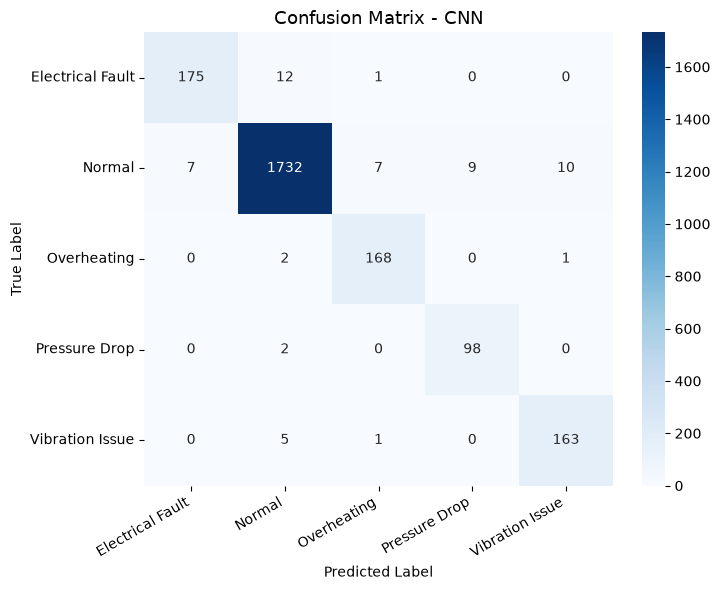

LSTM                  Acc=0.9770  Prec=0.9776  Rec=0.9770  F1=0.9771


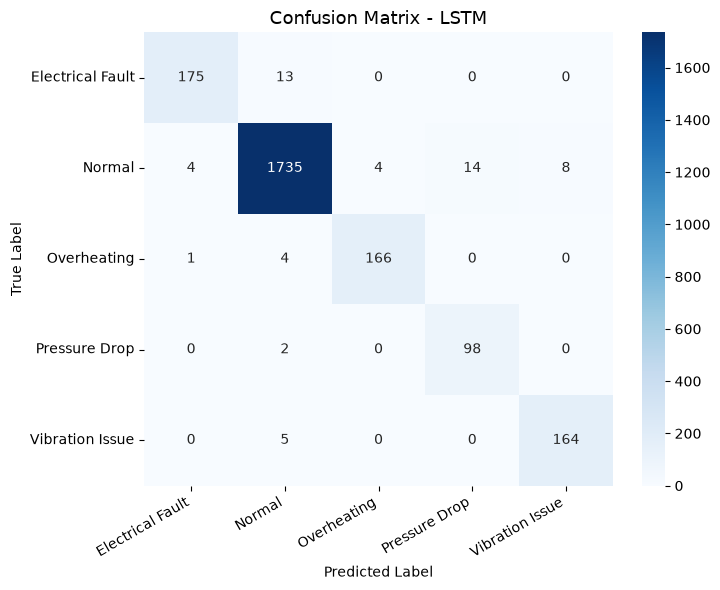

CNN+LSTM Ensemble     Acc=0.9808  Prec=0.9809  Rec=0.9808  F1=0.9808


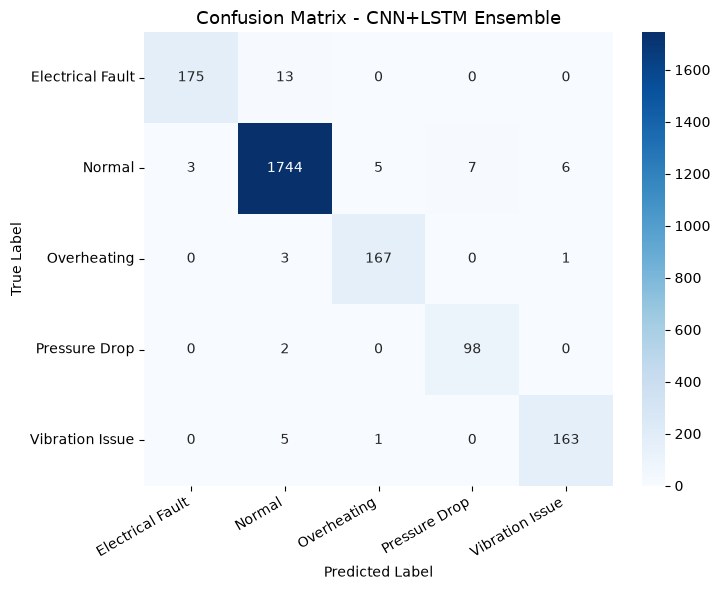

Bayesian Network      Acc=0.9712  Prec=0.9724  Rec=0.9712  F1=0.9715


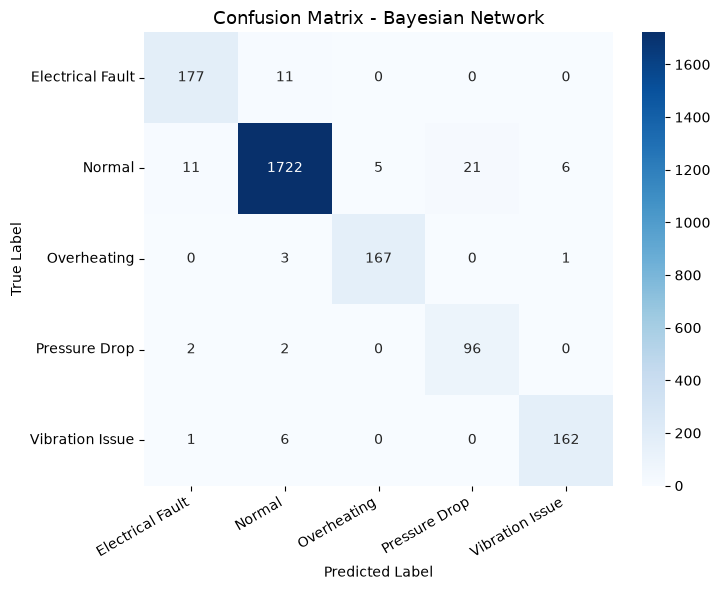

CNN+LSTM+BN (Final Hybrid)  Acc=0.9712  Prec=0.9724  Rec=0.9712  F1=0.9715


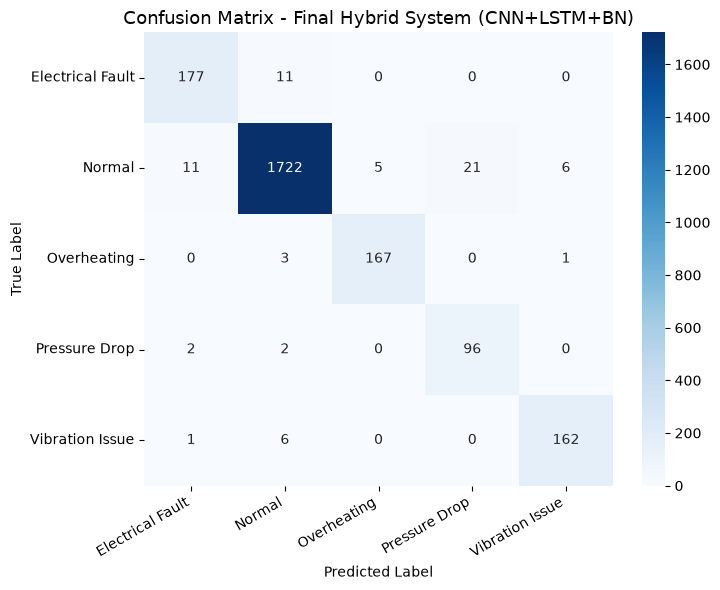


Model comparison table:
                         Model  Accuracy  Precision  Recall      F1
0                         CNN    0.9762     0.9765  0.9762  0.9762
1                        LSTM    0.9770     0.9776  0.9770  0.9771
2           CNN+LSTM Ensemble    0.9808     0.9809  0.9808  0.9808
3            Bayesian Network    0.9712     0.9724  0.9712  0.9715
4  CNN+LSTM+BN (Final Hybrid)    0.9712     0.9724  0.9712  0.9715

Detailed classification report (Final Hybrid):
                   precision    recall  f1-score   support

Electrical Fault       0.93      0.94      0.93       188
          Normal       0.99      0.98      0.98      1765
     Overheating       0.97      0.98      0.97       171
   Pressure Drop       0.82      0.96      0.88       100
 Vibration Issue       0.96      0.96      0.96       169

        accuracy                           0.97      2393
       macro avg       0.93      0.96      0.95      2393
    weighted avg       0.97      0.97      0.97      2393

In [2]:
# ============================================================================
# STEP 0: DEPENDENCY SETUP (run this in a FRESH kernel — restart first!)
# ============================================================================
%pip install --upgrade --force-reinstall scikit-learn -q
%pip install --upgrade pgmpy imbalanced-learn tensorflow-cpu pandas matplotlib seaborn -q

"""
EXPLAINABLE MACHINE FAULT DIAGNOSIS USING CNN/LSTM + BAYESIAN NETWORKS
========================================================================
Single-cell, end-to-end version: generates a synthetic Industrial IoT
dataset, then runs the full CNN/LSTM + Bayesian Network pipeline.

To use your OWN real dataset instead: comment out the "PHASE 1" block below
and load your CSV instead, as long as it has these columns:
Machine_ID, Timestamp, Temperature, Vibration, Humidity, Pressure,
Energy_Consumption, Failure_Type, Anomaly_Flag
"""

import os
import time
import logging
import warnings
warnings.filterwarnings("ignore")

# Suppress noisy pgmpy INFO/WARNING messages (harmless floating-point
# rounding notices during Bayesian Network inference)
logging.getLogger("pgmpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, Flatten, Dense,
                                      LSTM, Dropout, Input)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination, ApproxInference
# NOTE: MaximumLikelihoodEstimator is no longer imported/passed explicitly.
# Recent pgmpy versions require `fit()`'s estimator argument to be an
# *instance* of a DiscreteParameterEstimator subclass, not the bare
# MaximumLikelihoodEstimator class used in older tutorials. Since Maximum
# Likelihood is already pgmpy's default estimator, we simply omit the
# argument below (see PHASE 8-11) instead of chasing the exact class name/
# import path across versions.

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

FEATURES = ["Temperature", "Vibration", "Humidity", "Pressure", "Energy_Consumption"]
TIME_STEPS = 20   # sequence length used for CNN/LSTM

# ============================================================================
# PHASE 1: DATASET GENERATION
# Replace this whole block with `df = pd.read_csv('your_file.csv', parse_dates=['Timestamp'])`
# if you already have a real sensor dataset.
# ============================================================================
print("=" * 70)
print("PHASE 1: DATASET GENERATION")
print("=" * 70)

N_MACHINES = 8
READINGS_PER_MACHINE = 6000
START_TIME = pd.Timestamp("2025-01-01 00:00:00")
FREQ_MINUTES = 5

BASE = dict(temperature=55, vibration=20, humidity=45, pressure=100, energy=40)
NOISE = dict(temperature=3, vibration=3, humidity=4, pressure=4, energy=5)

FAULT_SIGNATURE = {
    "Overheating":      dict(temperature=+32, vibration=+6,  humidity=+2,  pressure=+1,  energy=+18),
    "Vibration Issue":  dict(temperature=+4,  vibration=+28, humidity=+1,  pressure=-2,  energy=+8),
    "Pressure Drop":    dict(temperature=+2,  vibration=+3,  humidity=-1,  pressure=-30, energy=+3),
    "Electrical Fault": dict(temperature=+6,  vibration=+5,  humidity=+1,  pressure=-1,  energy=+26),
}

rows = []
for m in range(N_MACHINES):
    machine_id = f"M{m+1:03d}"
    timestamp = START_TIME
    idx = 0
    while idx < READINGS_PER_MACHINE:
        healthy_len = min(np.random.randint(120, 400), READINGS_PER_MACHINE - idx)
        for _ in range(healthy_len):
            temperature = np.random.normal(BASE["temperature"], NOISE["temperature"])
            vibration = max(0, np.random.normal(BASE["vibration"], NOISE["vibration"]))
            humidity = np.random.normal(BASE["humidity"], NOISE["humidity"])
            pressure = np.random.normal(BASE["pressure"], NOISE["pressure"])
            energy = max(0, np.random.normal(BASE["energy"], NOISE["energy"]))
            rows.append([machine_id, timestamp, round(temperature, 2), round(vibration, 2),
                         round(humidity, 2), round(pressure, 2), round(energy, 2), "Normal", 0])
            timestamp += pd.Timedelta(minutes=FREQ_MINUTES)
            idx += 1
        if idx >= READINGS_PER_MACHINE:
            break
        fault = np.random.choice(["Overheating", "Vibration Issue", "Pressure Drop", "Electrical Fault"])
        sig = FAULT_SIGNATURE[fault]
        fault_len = min(np.random.randint(40, 150), READINGS_PER_MACHINE - idx)
        ramp = max(5, fault_len // 5)
        for k in range(fault_len):
            severity = min(1.0, (k + 1) / ramp)
            temperature = np.random.normal(BASE["temperature"] + sig["temperature"] * severity, NOISE["temperature"])
            vibration = max(0, np.random.normal(BASE["vibration"] + sig["vibration"] * severity, NOISE["vibration"]))
            humidity = np.random.normal(BASE["humidity"] + sig["humidity"] * severity, NOISE["humidity"])
            pressure = np.random.normal(BASE["pressure"] + sig["pressure"] * severity, NOISE["pressure"])
            energy = max(0, np.random.normal(BASE["energy"] + sig["energy"] * severity, NOISE["energy"]))
            rows.append([machine_id, timestamp, round(temperature, 2), round(vibration, 2),
                         round(humidity, 2), round(pressure, 2), round(energy, 2), fault, 1])
            timestamp += pd.Timedelta(minutes=FREQ_MINUTES)
            idx += 1

df = pd.DataFrame(rows, columns=["Machine_ID", "Timestamp", "Temperature", "Vibration",
                                  "Humidity", "Pressure", "Energy_Consumption",
                                  "Failure_Type", "Anomaly_Flag"])

df["Machine_Status"] = np.where(df["Anomaly_Flag"] == 1, "Fault", "Running")
df["Maintenance_Requirement"] = np.where(df["Failure_Type"].isin(["Overheating", "Electrical Fault"]), "Urgent",
                                  np.where(df["Failure_Type"] == "Normal", "None", "Scheduled"))

rng = np.random.default_rng(0)
miss_idx = rng.choice(df.index, size=int(0.002 * len(df)), replace=False)
df.loc[miss_idx, "Humidity"] = np.nan
dup_rows = df.sample(50, random_state=1)
df = pd.concat([df, dup_rows], ignore_index=True)

print("Generated dataset:", df.shape)
print(df["Failure_Type"].value_counts())

# ============================================================================
# PHASE 2: DATA PREPROCESSING
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 2: DATA PREPROCESSING")
print("=" * 70)

print("Missing values before cleaning:\n", df.isnull().sum())

for col in FEATURES:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows")

df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["Hour"] = df["Timestamp"].dt.hour
df["Day"] = df["Timestamp"].dt.day
df["Month"] = df["Timestamp"].dt.month

df = df.sort_values(["Machine_ID", "Timestamp"]).reset_index(drop=True)
print("Missing values after cleaning:\n", df.isnull().sum().sum(), "(total)")

# ============================================================================
# PHASE 4: FEATURE ENGINEERING / TARGET SETUP
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 4: FEATURE ENGINEERING")
print("=" * 70)

label_encoder = LabelEncoder()
df["Failure_Type_Encoded"] = label_encoder.fit_transform(df["Failure_Type"])
CLASS_NAMES = list(label_encoder.classes_)
N_CLASSES = len(CLASS_NAMES)
print("Fault classes:", CLASS_NAMES)

scaler = StandardScaler()
df[FEATURES] = scaler.fit_transform(df[FEATURES])

# ============================================================================
# PHASE 5: SEQUENCE CREATION FOR CNN/LSTM
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 5: SEQUENCE CREATION")
print("=" * 70)


def build_sequences(frame, time_steps=TIME_STEPS, stride=3):
    X, y_multiclass, y_binary = [], [], []
    for machine_id, g in frame.groupby("Machine_ID"):
        g = g.reset_index(drop=True)
        feats = g[FEATURES].values
        labels = g["Failure_Type_Encoded"].values
        anomaly = g["Anomaly_Flag"].values
        for start in range(0, len(g) - time_steps, stride):
            end = start + time_steps
            X.append(feats[start:end])
            y_multiclass.append(labels[end - 1])
            y_binary.append(anomaly[end - 1])
    return np.array(X), np.array(y_multiclass), np.array(y_binary)


X, y_multi, y_bin = build_sequences(df)
print("Sequence tensor shape (samples, time_steps, features):", X.shape)
print("Multiclass label distribution:",
      pd.Series(y_multi).map(dict(enumerate(CLASS_NAMES))).value_counts().to_dict())

X_train, X_temp, y_train, y_temp, ybin_train, ybin_temp = train_test_split(
    X, y_multi, y_bin, test_size=0.30, random_state=SEED, stratify=y_multi)
X_val, X_test, y_val, y_test, ybin_val, ybin_test = train_test_split(
    X_temp, y_temp, ybin_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f"Train: {X_train.shape[0]}  Val: {X_val.shape[0]}  Test: {X_test.shape[0]}")

# ============================================================================
# PHASE 3: DATA BALANCING
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 3: DATA BALANCING")
print("=" * 70)

classes_present = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes_present, y=y_train)
class_weight_dict = {int(c): float(w) for c, w in zip(classes_present, weights)}
print("Class weights (for CNN/LSTM):", class_weight_dict)

X_train_flat = X_train[:, -1, :]
smote = SMOTE(random_state=SEED, k_neighbors=3)
X_train_bn, y_train_bn = smote.fit_resample(X_train_flat, y_train)
print("Before SMOTE:", pd.Series(y_train).value_counts().to_dict())
print("After  SMOTE:", pd.Series(y_train_bn).value_counts().to_dict())

y_train_cat = to_categorical(y_train, N_CLASSES)
y_val_cat = to_categorical(y_val, N_CLASSES)
y_test_cat = to_categorical(y_test, N_CLASSES)

# ============================================================================
# PHASE 6/7: CNN, LSTM, ENSEMBLE
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 6 & 7: CNN / LSTM MODELS + ENSEMBLE")
print("=" * 70)

n_features = X_train.shape[2]
early_stop = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)


def build_cnn():
    model = Sequential([
        Input(shape=(TIME_STEPS, n_features)),
        Conv1D(64, kernel_size=3, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Conv1D(32, kernel_size=3, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(N_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model


def build_lstm():
    model = Sequential([
        Input(shape=(TIME_STEPS, n_features)),
        LSTM(64, return_sequences=True),
        Dropout(0.3),
        LSTM(32),
        Dense(32, activation="relu"),
        Dense(N_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model


print("\n--- Training CNN ---")
cnn_model = build_cnn()
cnn_model.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
              epochs=25, batch_size=128, class_weight=class_weight_dict,
              callbacks=[early_stop], verbose=2)

print("\n--- Training LSTM ---")
lstm_model = build_lstm()
lstm_model.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat),
               epochs=25, batch_size=128, class_weight=class_weight_dict,
               callbacks=[early_stop], verbose=2)

cnn_probs_test = cnn_model.predict(X_test, verbose=0)
lstm_probs_test = lstm_model.predict(X_test, verbose=0)
ensemble_probs_test = (cnn_probs_test + lstm_probs_test) / 2.0

cnn_pred = np.argmax(cnn_probs_test, axis=1)
lstm_pred = np.argmax(lstm_probs_test, axis=1)
ensemble_pred = np.argmax(ensemble_probs_test, axis=1)

# ============================================================================
# PHASE 8-11: BAYESIAN NETWORK
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 8-11: BAYESIAN NETWORK")
print("=" * 70)


def discretize(values, edges, labels):
    return pd.cut(values, bins=edges, labels=labels, include_lowest=True)


def make_bin_edges(col_values, n_bins=3):
    qs = np.quantile(col_values, np.linspace(0, 1, n_bins + 1))
    qs[0] -= 1e-6
    qs[-1] += 1e-6
    return qs


STATE_LABELS = ["Low", "Medium", "High"]
bin_edges = {f: make_bin_edges(X_train_bn[:, i]) for i, f in enumerate(FEATURES)}

bn_train_df = pd.DataFrame(X_train_bn, columns=FEATURES)
for f in FEATURES:
    bn_train_df[f + "_State"] = discretize(bn_train_df[f], bin_edges[f], STATE_LABELS)
bn_train_df["Failure_Type"] = [CLASS_NAMES[i] for i in y_train_bn]

cnn_probs_train = cnn_model.predict(X_train, verbose=0)
lstm_probs_train = lstm_model.predict(X_train, verbose=0)
ens_probs_train = (cnn_probs_train + lstm_probs_train) / 2.0
dl_pred_train_last = np.argmax(ens_probs_train, axis=1)

dl_pred_full = []
real_n = len(y_train)
dl_lookup = {}
for lbl in np.unique(y_train):
    dl_lookup[lbl] = dl_pred_train_last[y_train == lbl]
for i in range(len(y_train_bn)):
    if i < real_n:
        dl_pred_full.append(CLASS_NAMES[dl_pred_train_last[i]])
    else:
        lbl = y_train_bn[i]
        pool = dl_lookup[lbl]
        dl_pred_full.append(CLASS_NAMES[np.random.choice(pool)] if len(pool) else "Normal")
bn_train_df["DL_Prediction"] = dl_pred_full

bn_columns = [f + "_State" for f in FEATURES] + ["DL_Prediction", "Failure_Type"]
bn_data = bn_train_df[bn_columns].astype(str)

edges = [(f + "_State", "Failure_Type") for f in FEATURES] + [("DL_Prediction", "Failure_Type")]
bn_model = DiscreteBayesianNetwork(edges)

# --- FIX ---
# Older pgmpy accepted `fit(data, estimator=MaximumLikelihoodEstimator)` by
# passing the *class* itself. Newer pgmpy validates that `estimator` is an
# *instance* of a DiscreteParameterEstimator subclass, so passing the bare
# class raises: "TypeError: Estimator should be an instance of a discrete
# parameter estimator." Maximum Likelihood is pgmpy's default estimator,
# so we just call fit() with no estimator argument at all.
bn_model.fit(bn_data)
# --- END FIX ---

print("Bayesian Network nodes:", bn_model.nodes())
print("CPT learned for Failure_Type with parents:",
      [p for p in bn_model.get_cpds("Failure_Type").variables if p != "Failure_Type"])

ve_engine = VariableElimination(bn_model)


def discretize_row(row_features):
    states = {}
    for i, f in enumerate(FEATURES):
        val = row_features[i]
        edges_f = bin_edges[f]
        idx = np.digitize([val], edges_f)[0] - 1
        idx = min(max(idx, 0), len(STATE_LABELS) - 1)
        states[f + "_State"] = STATE_LABELS[idx]
    return states


_ve_cache = {}


def _ve_query_cached(evidence_tuple):
    if evidence_tuple in _ve_cache:
        return _ve_cache[evidence_tuple]
    evidence = dict(zip([f + "_State" for f in FEATURES] + ["DL_Prediction"], evidence_tuple))
    try:
        result = ve_engine.map_query(variables=["Failure_Type"], evidence=evidence, show_progress=False)
        pred = CLASS_NAMES.index(result["Failure_Type"])
    except Exception:
        pred = None
    _ve_cache[evidence_tuple] = pred
    return pred


def bn_predict_batch(X_last_features, dl_predictions):
    preds = []
    for feats, dl_pred_idx in zip(X_last_features, dl_predictions):
        evidence = discretize_row(feats)
        state_tuple = tuple(evidence[f + "_State"] for f in FEATURES) + (CLASS_NAMES[dl_pred_idx],)
        pred = _ve_query_cached(state_tuple)
        preds.append(pred if pred is not None else dl_pred_idx)
    return np.array(preds)


X_test_last = X_test[:, -1, :]
bn_pred = bn_predict_batch(X_test_last, ensemble_pred)

# ============================================================================
# PHASE 12: EXPLAINABILITY LAYER
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 12: EXPLAINABLE FAULT DIAGNOSIS")
print("=" * 70)

_posterior_cache = {}


def _posterior_query_cached(evidence):
    key = tuple(sorted(evidence.items()))
    if key in _posterior_cache:
        return _posterior_cache[key]
    try:
        posterior = ve_engine.query(variables=["Failure_Type"], evidence=evidence, show_progress=False)
        probs = dict(zip(posterior.state_names["Failure_Type"], posterior.values))
    except Exception:
        probs = None
    _posterior_cache[key] = probs
    return probs


def explain_prediction(sample_features, dl_probs, sample_idx=None):
    dl_pred_idx = int(np.argmax(dl_probs))
    dl_conf = float(np.max(dl_probs))
    evidence = discretize_row(sample_features)
    evidence["DL_Prediction"] = CLASS_NAMES[dl_pred_idx]
    probs = _posterior_query_cached(evidence)
    if probs is None:
        probs = {CLASS_NAMES[dl_pred_idx]: dl_conf}
    best_fault = max(probs, key=probs.get)
    confidence = probs[best_fault]

    reasons = []
    for f in FEATURES:
        state = evidence[f + "_State"]
        if state == "High" and f != "Pressure":
            reasons.append(f"{f.replace('_', ' ')} reading is abnormally HIGH")
        if state == "Low" and f == "Pressure":
            reasons.append("Pressure reading is abnormally LOW")
    reasons.append(f"Deep-learning model (CNN+LSTM) predicted '{CLASS_NAMES[dl_pred_idx]}' "
                    f"with {dl_conf * 100:.1f}% confidence")
    if not reasons:
        reasons.append("All sensor readings are within the normal operating range")

    status = "FAULT" if best_fault != "Normal" else "HEALTHY"
    return {
        "sample_index": sample_idx,
        "machine_status": status,
        "most_probable_fault": best_fault,
        "confidence": round(confidence * 100, 2),
        "fault_probability_breakdown": {k: round(v * 100, 2) for k, v in probs.items()},
        "reasons": reasons,
    }


sample_reports = []
sample_positions = np.random.choice(len(X_test), size=8, replace=False)
for pos in sample_positions:
    rep = explain_prediction(X_test_last[pos], ensemble_probs_test[pos], sample_idx=int(pos))
    sample_reports.append(rep)

with open(os.path.join(OUT_DIR, "sample_explainable_reports.txt"), "w") as f:
    for rep in sample_reports:
        f.write(f"Sample #{rep['sample_index']}\n")
        f.write(f"  Machine Status : {rep['machine_status']}\n")
        f.write(f"  Most Probable Fault : {rep['most_probable_fault']} "
                f"(confidence {rep['confidence']}%)\n")
        f.write(f"  Full Probability Breakdown : {rep['fault_probability_breakdown']}\n")
        f.write("  Reasons:\n")
        for r in rep["reasons"]:
            f.write(f"    - {r}\n")
        f.write("\n")

print("Saved sample explainable reports ->", os.path.join(OUT_DIR, "sample_explainable_reports.txt"))
print("\nExample report:\n", sample_reports[0])

# ============================================================================
# PHASE 13: MODEL EVALUATION + CONFUSION MATRICES
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 13: MODEL EVALUATION")
print("=" * 70)


def plot_confusion(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, cbar=True, annot_kws={"size": 10})
    plt.title(title, fontsize=13)
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, filename), dpi=150)
    plt.show()
    plt.close()
    return cm


def summarize(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    print(f"{name:20s}  Acc={acc:.4f}  Prec={prec:.4f}  Rec={rec:.4f}  F1={f1:.4f}")
    return dict(Model=name, Accuracy=round(acc, 4), Precision=round(prec, 4),
                Recall=round(rec, 4), F1=round(f1, 4))


results = []
results.append(summarize("CNN", y_test, cnn_pred))
plot_confusion(y_test, cnn_pred, "Confusion Matrix - CNN", "confusion_matrix_cnn.png")

results.append(summarize("LSTM", y_test, lstm_pred))
plot_confusion(y_test, lstm_pred, "Confusion Matrix - LSTM", "confusion_matrix_lstm.png")

results.append(summarize("CNN+LSTM Ensemble", y_test, ensemble_pred))
plot_confusion(y_test, ensemble_pred, "Confusion Matrix - CNN+LSTM Ensemble", "confusion_matrix_ensemble.png")

results.append(summarize("Bayesian Network", y_test, bn_pred))
plot_confusion(y_test, bn_pred, "Confusion Matrix - Bayesian Network", "confusion_matrix_bayesian_network.png")

results.append(summarize("CNN+LSTM+BN (Final Hybrid)", y_test, bn_pred))
plot_confusion(y_test, bn_pred, "Confusion Matrix - Final Hybrid System (CNN+LSTM+BN)",
               "confusion_matrix_final_hybrid.png")

results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(OUT_DIR, "model_comparison_table.csv"), index=False)
print("\nModel comparison table:\n", results_df)

print("\nDetailed classification report (Final Hybrid):\n",
      classification_report(y_test, bn_pred, target_names=CLASS_NAMES, zero_division=0))

# ============================================================================
# PHASE 14: EXACT vs APPROXIMATE INFERENCE COMPARISON
# ============================================================================
print("\n" + "=" * 70)
print("PHASE 14: EXACT (Variable Elimination) vs APPROXIMATE (Sampling) INFERENCE")
print("=" * 70)

N_EVAL = min(300, len(X_test_last))
eval_idx = np.random.choice(len(X_test_last), size=N_EVAL, replace=False)

t0 = time.time()
ve_preds = bn_predict_batch(X_test_last[eval_idx], ensemble_pred[eval_idx])
ve_time = time.time() - t0
ve_acc = accuracy_score(y_test[eval_idx], ve_preds)

approx_engine = ApproxInference(bn_model)
_approx_cache = {}


def bn_predict_approx(X_last_features, dl_predictions, n_samples=200):
    preds = []
    for feats, dl_pred_idx in zip(X_last_features, dl_predictions):
        evidence = discretize_row(feats)
        evidence["DL_Prediction"] = CLASS_NAMES[dl_pred_idx]
        key = tuple(sorted(evidence.items()))
        if key in _approx_cache:
            preds.append(_approx_cache[key])
            continue
        try:
            posterior = approx_engine.query(variables=["Failure_Type"], evidence=evidence,
                                             n_samples=n_samples, show_progress=False)
            probs = dict(zip(posterior.state_names["Failure_Type"], posterior.values))
            pred = CLASS_NAMES.index(max(probs, key=probs.get))
        except Exception:
            pred = dl_pred_idx
        _approx_cache[key] = pred
        preds.append(pred)
    return np.array(preds)


t0 = time.time()
approx_preds = bn_predict_approx(X_test_last[eval_idx], ensemble_pred[eval_idx])
approx_time = time.time() - t0
approx_acc = accuracy_score(y_test[eval_idx], approx_preds)

inference_comparison = pd.DataFrame([
    {"Method": "Variable Elimination (exact)", "Accuracy": round(ve_acc, 4), "Time_seconds": round(ve_time, 3)},
    {"Method": "Likelihood-Weighted Sampling (approx.)", "Accuracy": round(approx_acc, 4), "Time_seconds": round(approx_time, 3)},
])
inference_comparison.to_csv(os.path.join(OUT_DIR, "inference_method_comparison.csv"), index=False)
print(inference_comparison)

# ============================================================================
# DONE
# ============================================================================
print("\n" + "=" * 70)
print("ALL PHASES COMPLETE. Outputs saved to:", OUT_DIR)
print("=" * 70)
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

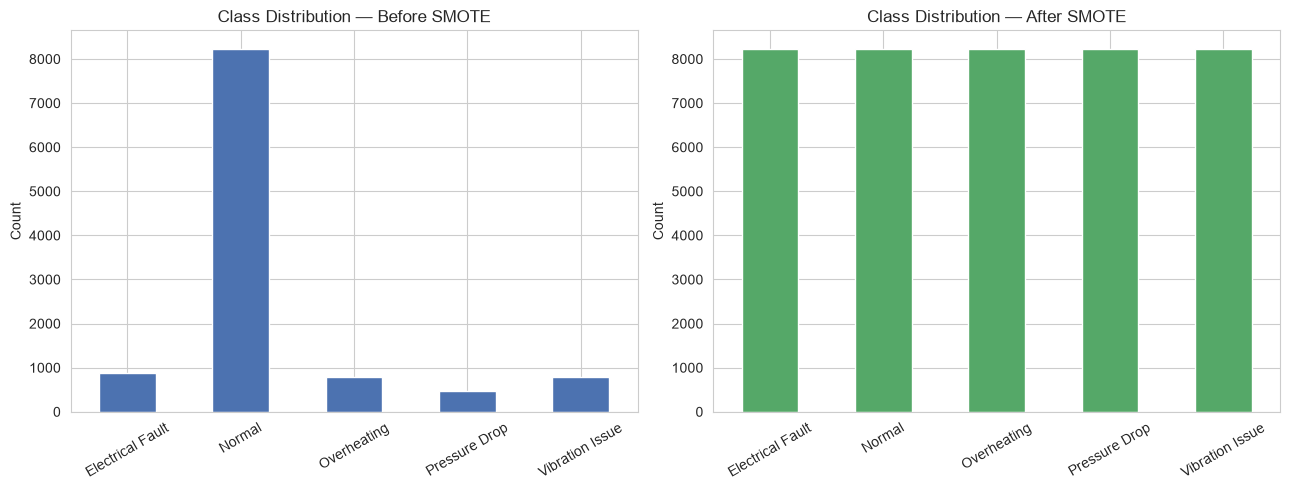

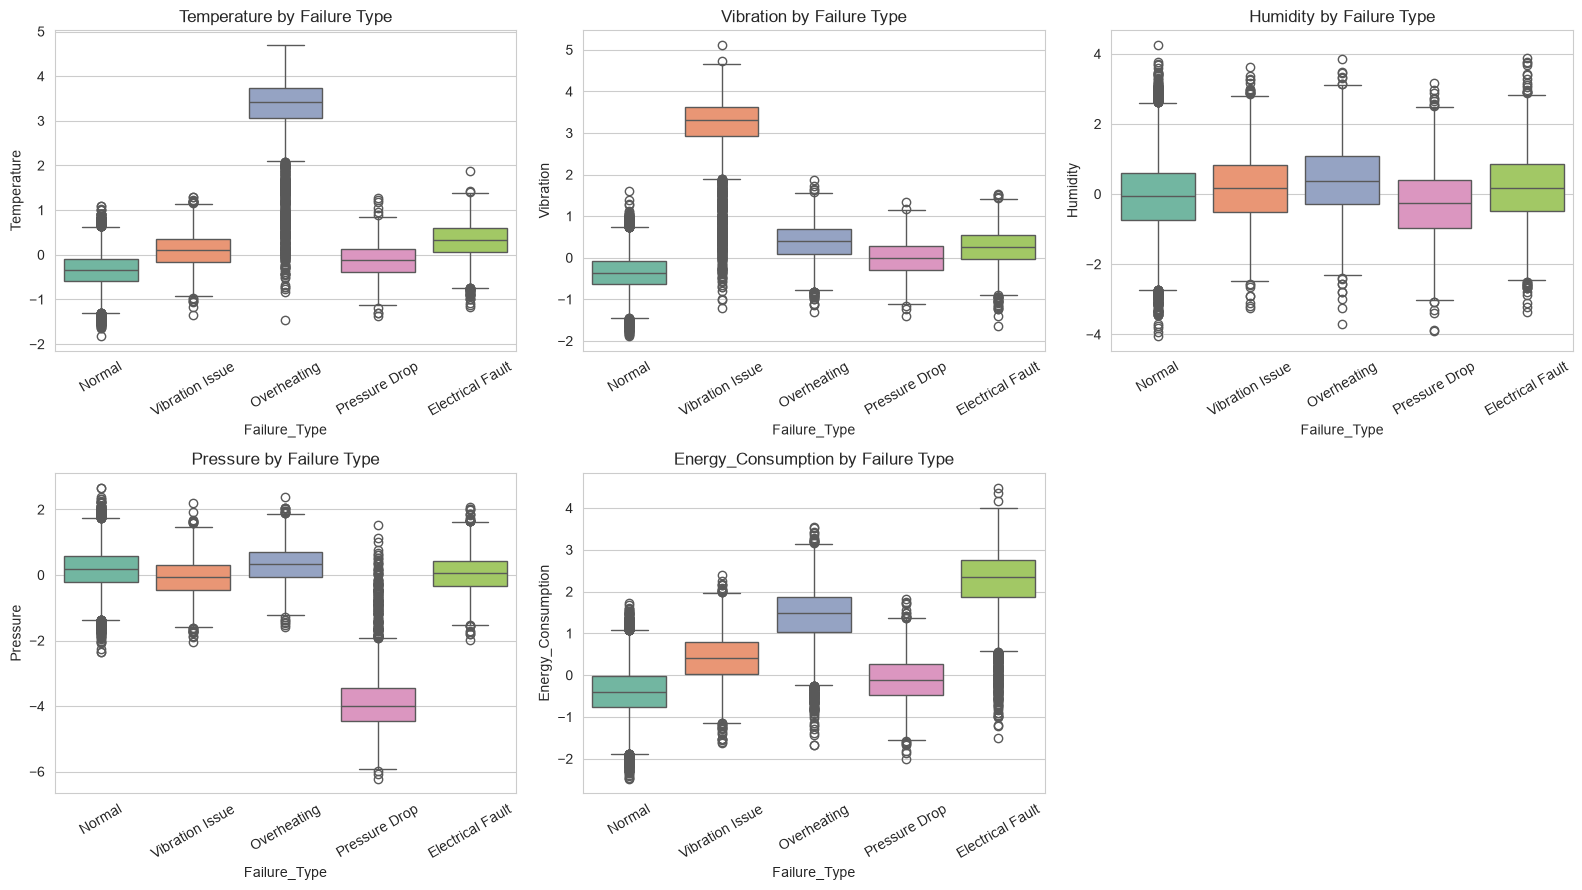

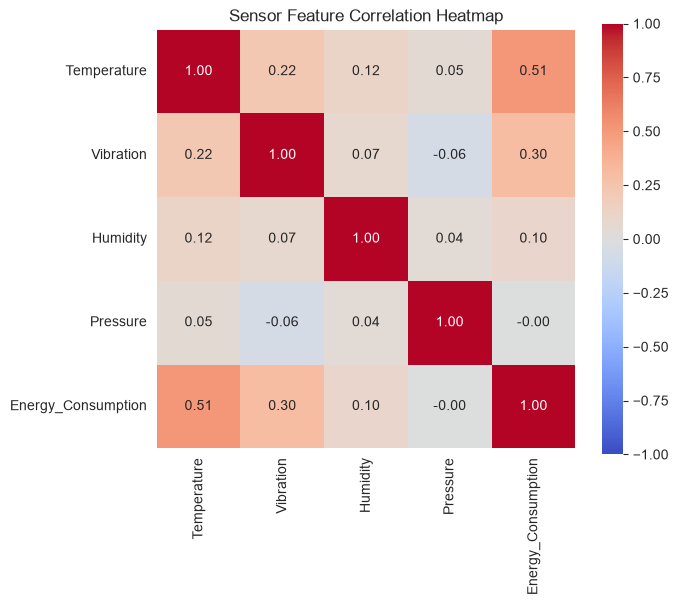

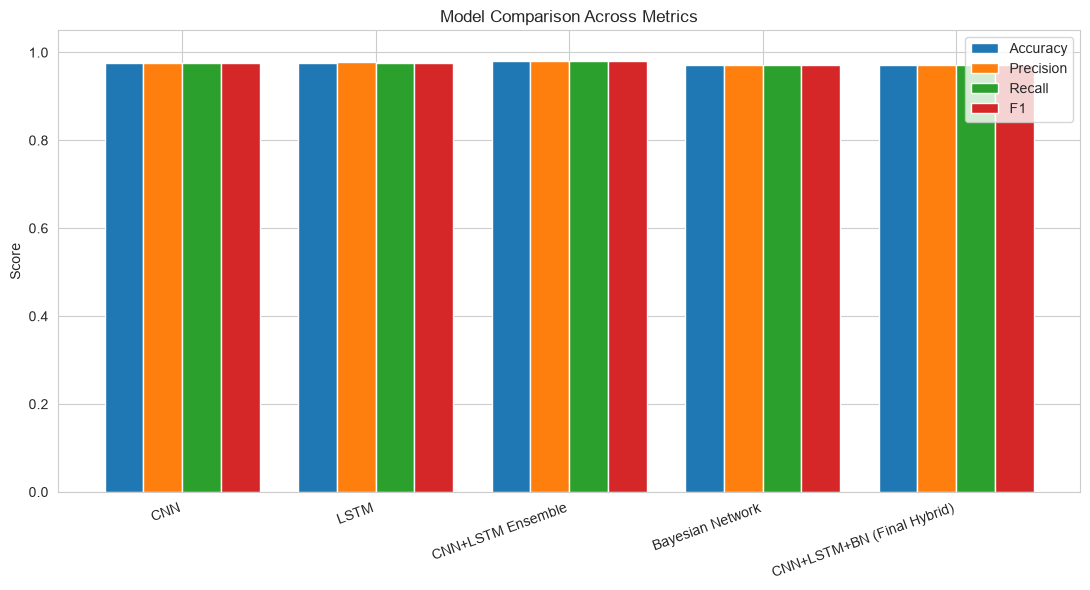

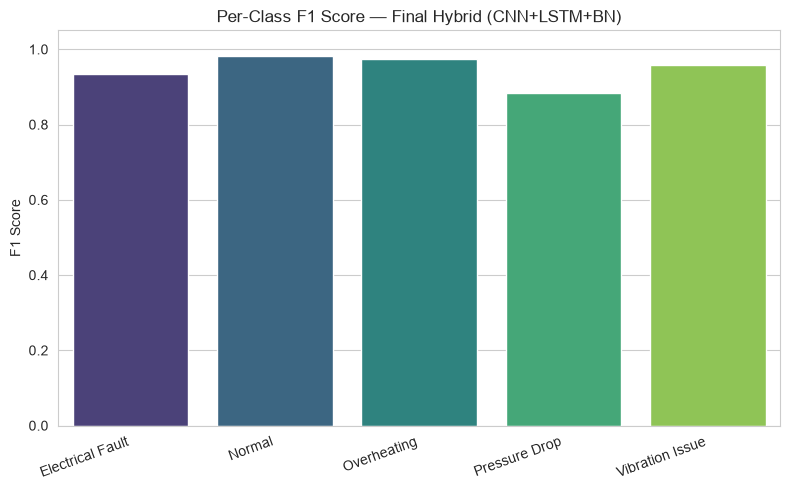

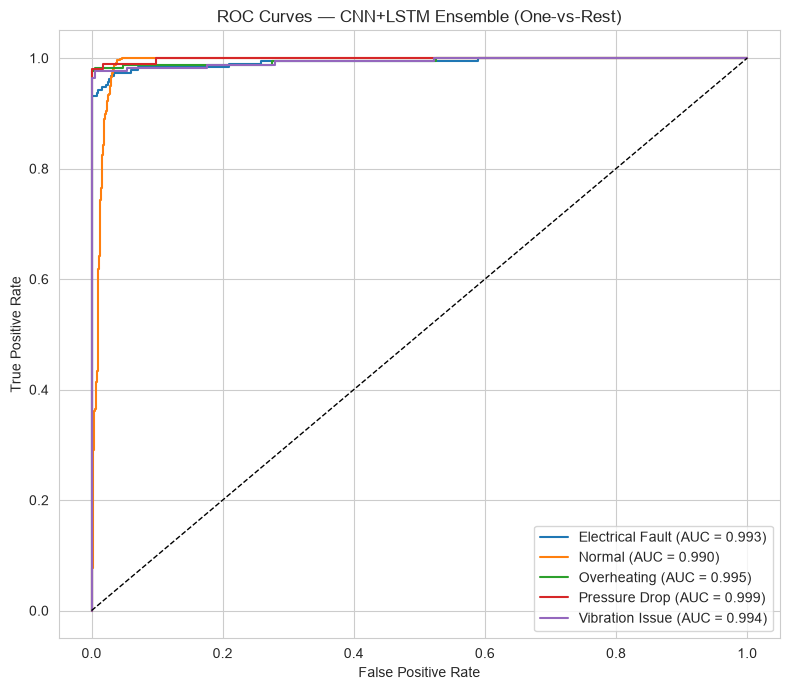

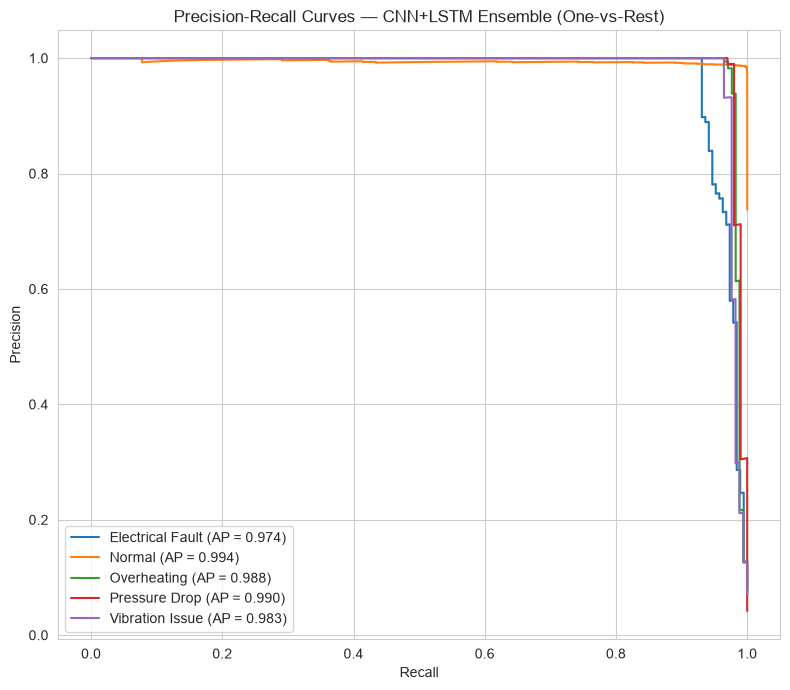

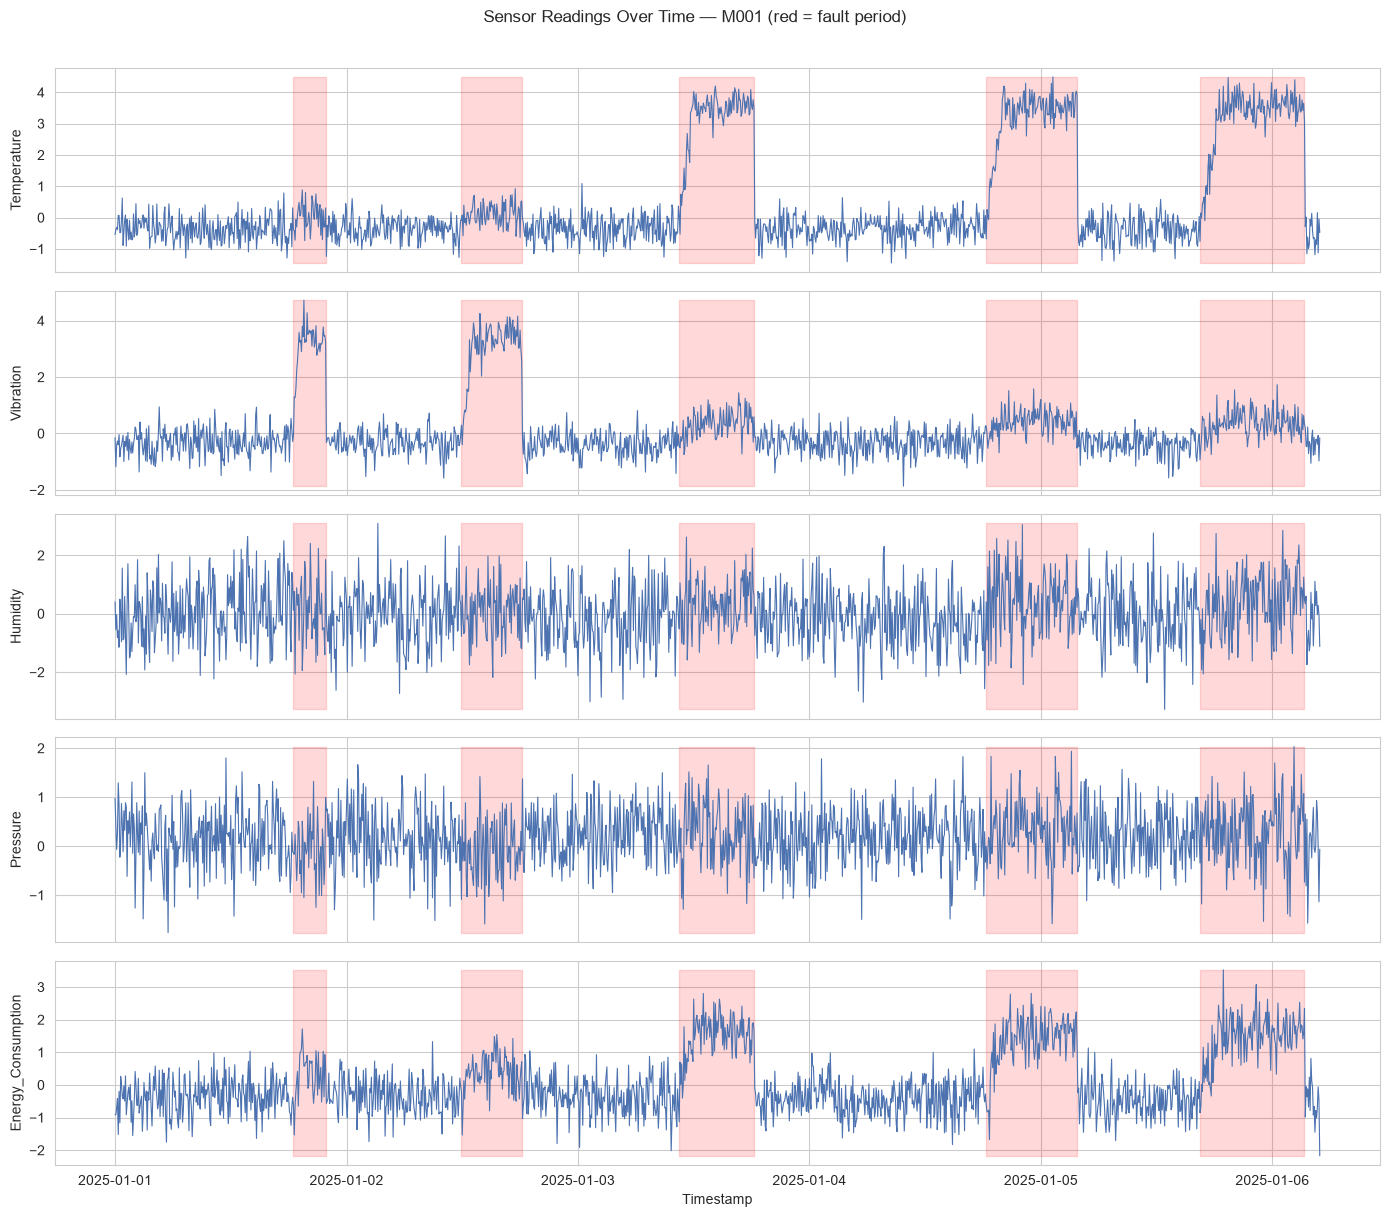

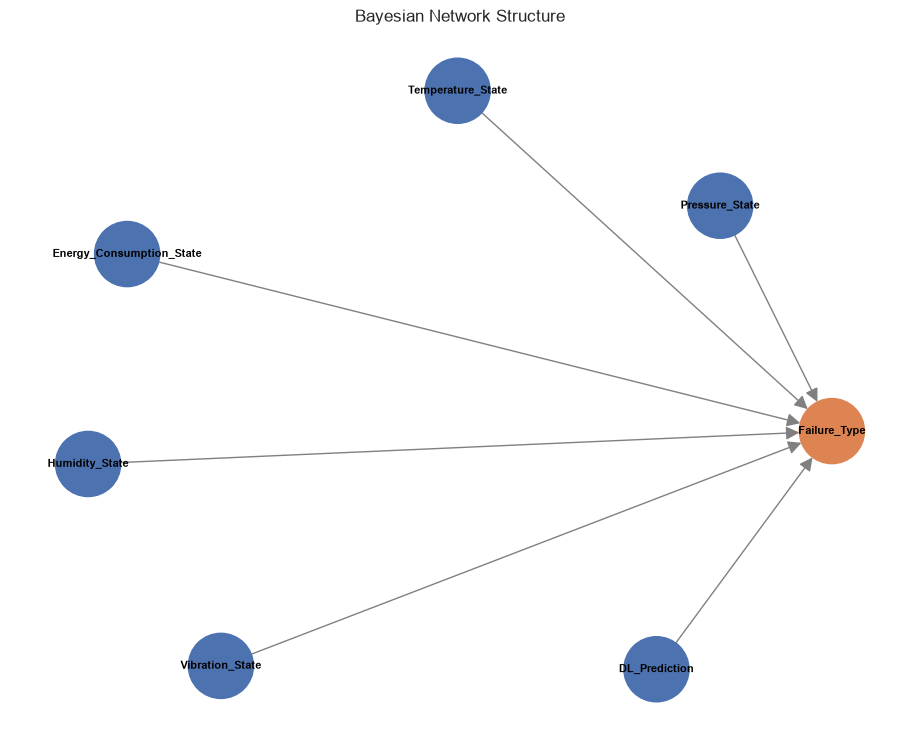

Skipping training-curve plot: cnn_history/lstm_history not found. See the NOTE above this block for how to capture them.

All extra plots saved to: outputs
 - bayesian_network_structure.png
 - class_distribution_before_after_smote.png
 - confusion_matrix_bayesian_network.png
 - confusion_matrix_cnn.png
 - confusion_matrix_ensemble.png
 - confusion_matrix_final_hybrid.png
 - confusion_matrix_lstm.png
 - feature_correlation_heatmap.png
 - feature_distributions_by_fault.png
 - inference_method_comparison.csv
 - model_comparison_bar_chart.png
 - model_comparison_table.csv
 - per_class_f1_final_hybrid.png
 - precision_recall_curves_ensemble.png
 - roc_curves_ensemble.png
 - sample_explainable_reports.txt
 - sensor_timeseries_sample_machine.png


In [3]:
# ============================================================================
# EXTRA PLOTS — paste this in a NEW cell AFTER the main script has finished
# running (it reuses variables like df, X_train_bn, y_train_bn, results_df,
# ensemble_probs_test, bn_model, etc. that already exist in memory).
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

sns.set_style("whitegrid")

# ----------------------------------------------------------------------------
# 1. CLASS DISTRIBUTION — BEFORE vs AFTER SMOTE
# ----------------------------------------------------------------------------
before_counts = pd.Series(y_train).map(dict(enumerate(CLASS_NAMES))).value_counts()
after_counts = pd.Series(y_train_bn).map(dict(enumerate(CLASS_NAMES))).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
before_counts.reindex(CLASS_NAMES).plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Class Distribution — Before SMOTE")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=30)

after_counts.reindex(CLASS_NAMES).plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Class Distribution — After SMOTE")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "class_distribution_before_after_smote.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 2. FEATURE DISTRIBUTIONS BY FAULT TYPE (boxplots)
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, feat in enumerate(FEATURES):
    sns.boxplot(data=df, x="Failure_Type", y=feat, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{feat} by Failure Type")
    axes[i].tick_params(axis="x", rotation=30)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "feature_distributions_by_fault.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 3. SENSOR CORRELATION HEATMAP
# ----------------------------------------------------------------------------
plt.figure(figsize=(7, 6))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Sensor Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "feature_correlation_heatmap.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 4. MODEL COMPARISON — GROUPED BAR CHART (Accuracy/Precision/Recall/F1)
# ----------------------------------------------------------------------------
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(results_df))
width = 0.2

plt.figure(figsize=(11, 6))
for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, results_df[metric], width, label=metric)
plt.xticks(x + width * 1.5, results_df["Model"], rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Model Comparison Across Metrics")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "model_comparison_bar_chart.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 5. PER-CLASS F1 SCORE (Final Hybrid model) — bar chart
# ----------------------------------------------------------------------------
from sklearn.metrics import f1_score as _f1

per_class_f1 = _f1(y_test, bn_pred, average=None, labels=range(N_CLASSES), zero_division=0)
plt.figure(figsize=(8, 5))
sns.barplot(x=CLASS_NAMES, y=per_class_f1, palette="viridis")
plt.title("Per-Class F1 Score — Final Hybrid (CNN+LSTM+BN)")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_class_f1_final_hybrid.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 6. ROC CURVES (one-vs-rest, multiclass) — CNN+LSTM Ensemble probabilities
# ----------------------------------------------------------------------------
y_test_bin = label_binarize(y_test, classes=range(N_CLASSES))

plt.figure(figsize=(8, 7))
for i, cls in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], ensemble_probs_test[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — CNN+LSTM Ensemble (One-vs-Rest)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "roc_curves_ensemble.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 7. PRECISION-RECALL CURVES (one-vs-rest, multiclass)
# ----------------------------------------------------------------------------
plt.figure(figsize=(8, 7))
for i, cls in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], ensemble_probs_test[:, i])
    ap = average_precision_score(y_test_bin[:, i], ensemble_probs_test[:, i])
    plt.plot(recall, precision, label=f"{cls} (AP = {ap:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — CNN+LSTM Ensemble (One-vs-Rest)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "precision_recall_curves_ensemble.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 8. RAW SENSOR TIME SERIES FOR ONE MACHINE, WITH FAULT PERIODS HIGHLIGHTED
# ----------------------------------------------------------------------------
sample_machine = df["Machine_ID"].unique()[0]
mdf = df[df["Machine_ID"] == sample_machine].sort_values("Timestamp").iloc[:1500]

fig, axes = plt.subplots(len(FEATURES), 1, figsize=(14, 12), sharex=True)
for i, feat in enumerate(FEATURES):
    axes[i].plot(mdf["Timestamp"], mdf[feat], color="#4C72B0", linewidth=0.8)
    fault_mask = mdf["Anomaly_Flag"] == 1
    axes[i].fill_between(mdf["Timestamp"], mdf[feat].min(), mdf[feat].max(),
                          where=fault_mask, color="red", alpha=0.15, step="mid")
    axes[i].set_ylabel(feat)
axes[-1].set_xlabel("Timestamp")
fig.suptitle(f"Sensor Readings Over Time — {sample_machine} (red = fault period)", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sensor_timeseries_sample_machine.png"), dpi=150)
plt.show()
plt.close()

# ----------------------------------------------------------------------------
# 9. BAYESIAN NETWORK STRUCTURE (DAG) VISUALIZATION
# ----------------------------------------------------------------------------
try:
    import networkx as nx

    plt.figure(figsize=(9, 7))
    G = nx.DiGraph()
    G.add_edges_from(bn_model.edges())
    pos = nx.spring_layout(G, seed=SEED, k=1.2)
    node_colors = ["#DD8452" if n == "Failure_Type" else "#4C72B0" for n in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=2200,
            font_size=8, font_weight="bold", arrowsize=20, edge_color="gray")
    plt.title("Bayesian Network Structure")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "bayesian_network_structure.png"), dpi=150)
    plt.show()
    plt.close()
except ImportError:
    print("networkx not installed — run `%pip install networkx -q` to get the BN structure plot.")

# ----------------------------------------------------------------------------
# 10. TRAINING CURVES (loss & accuracy) FOR CNN AND LSTM
# ----------------------------------------------------------------------------
# NOTE: the main script does not currently save the History objects returned
# by model.fit(), so `cnn_history` / `lstm_history` won't exist unless you
# capture them. If you want this plot, go back to the training cell and
# change these two lines:
#
#   cnn_model.fit(X_train, y_train_cat, ...)      ->  cnn_history = cnn_model.fit(X_train, y_train_cat, ...)
#   lstm_model.fit(X_train, y_train_cat, ...)      ->  lstm_history = lstm_model.fit(X_train, y_train_cat, ...)
#
# then re-run training and this block.
if "cnn_history" in dir() and "lstm_history" in dir():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for name, hist in [("CNN", cnn_history), ("LSTM", lstm_history)]:
        axes[0].plot(hist.history["loss"], label=f"{name} train")
        axes[0].plot(hist.history["val_loss"], "--", label=f"{name} val")
        axes[1].plot(hist.history["accuracy"], label=f"{name} train")
        axes[1].plot(hist.history["val_accuracy"], "--", label=f"{name} val")
    axes[0].set_title("Training/Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[1].set_title("Training/Validation Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "training_curves_cnn_lstm.png"), dpi=150)
    plt.show()
    plt.close()
else:
    print("Skipping training-curve plot: cnn_history/lstm_history not found. "
          "See the NOTE above this block for how to capture them.")

print("\nAll extra plots saved to:", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

In [1]:
import os

PROJECT_DIR = r"C:\Users\devin\Desktop\prob_project"

for root, dirs, files in os.walk(PROJECT_DIR):
    # Skip temporary notebook folders
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints", "__pycache__"]]

    for file in files:
        if file.lower().endswith((
            ".keras", ".h5", ".hdf5", ".weights.h5",
            ".pth", ".pt", ".pkl", ".joblib"
        )):
            print(os.path.join(root, file))
            

C:\Users\devin\Desktop\prob_project\dataset\best_machine_cnn.keras


In [2]:

import os
import tensorflow as tf

MODEL_PATH = r"C:\Users\devin\Desktop\prob_project\dataset\best_machine_cnn.keras"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

model = tf.keras.models.load_model(MODEL_PATH)

print("CNN model loaded successfully!")
model.summary()


CNN model loaded successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)             │ (None, 50, 64)        │        1,664 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ batch_normalization_6         │ (None, 50, 64)        │          256 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling1d_4               │ (None, 25, 64)        │            0 │
│ (MaxPooling1D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv1d_7 (Conv1D)             │ (None, 25, 128)       │       24,704 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ batch_normalization_7         │ (None, 25, 128)       │          512 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling1d_5               │ (None, 12, 128)       │            0 │
│ (MaxPooling1D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv1d_8 (Conv1D)             │ (None, 12, 128)       │       49,280 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ batch_normalization_8         │ (None, 12, 128)       │          512 │
│ (BatchNormalization)          │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ global_average_pooling1d_2    │ (None, 128)           │            0 │
│ (GlobalAveragePooling1D)      │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_4 (Dense)               │ (None, 128)           │       16,512 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_4 (Dropout)           │ (None, 128)           │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_5 (Dense)               │ (None, 1)             │          129 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 279,429 (1.07 MB)

 Trainable params: 92,929 (363.00 KB)

 Non-trainable params: 640 (2.50 KB)

 Optimizer params: 185,860 (726.02 KB)

SHAP EXPLAINABLE AI - MACHINE FAULT DIAGNOSIS
Dataset shape: (100000, 13)
Model input: (None, 50, 5)
Model output: (None, 1)
SHAP version: 0.51.0

Training rows: 80000
Test rows: 20000
Test sequences: (20000, 50, 5)
Test labels: (20000,)

CNN EVALUATION
Threshold: 0.5
Accuracy: 0.9094
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.5805
PR-AUC (average precision): 0.1238

Classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     18189
           1       0.00      0.00      0.00      1811

    accuracy                           0.91     20000
   macro avg       0.45      0.50      0.48     20000
weighted avg       0.83      0.91      0.87     20000



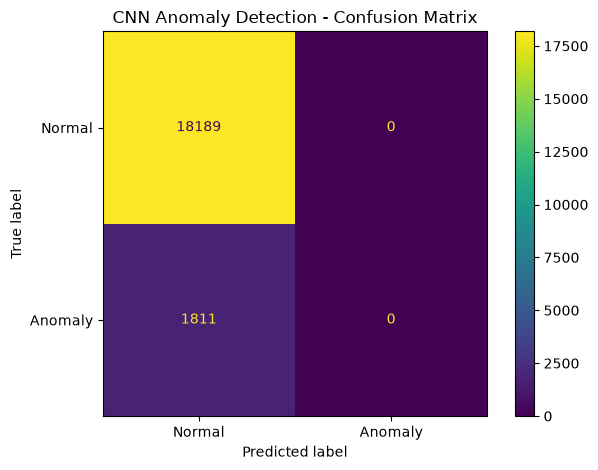


SHAP background samples: 20
Samples to explain: 30

Calculating SHAP values. This may take some time...
SHAP values shape: (30, 50, 5)

GLOBAL SHAP SENSOR IMPORTANCE
 rank             sensor  mean_absolute_shap
    1        temperature            0.001465
    2           humidity            0.001320
    3          vibration            0.001286
    4           pressure            0.001198
    5 energy_consumption            0.001189


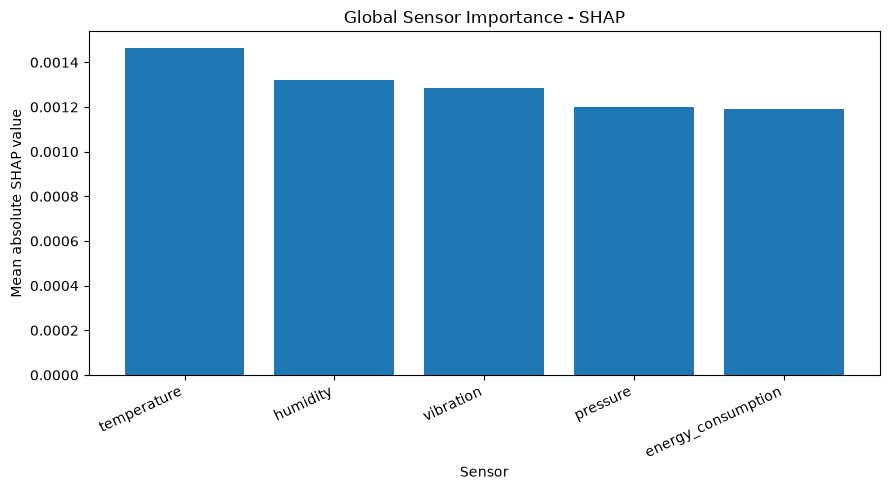

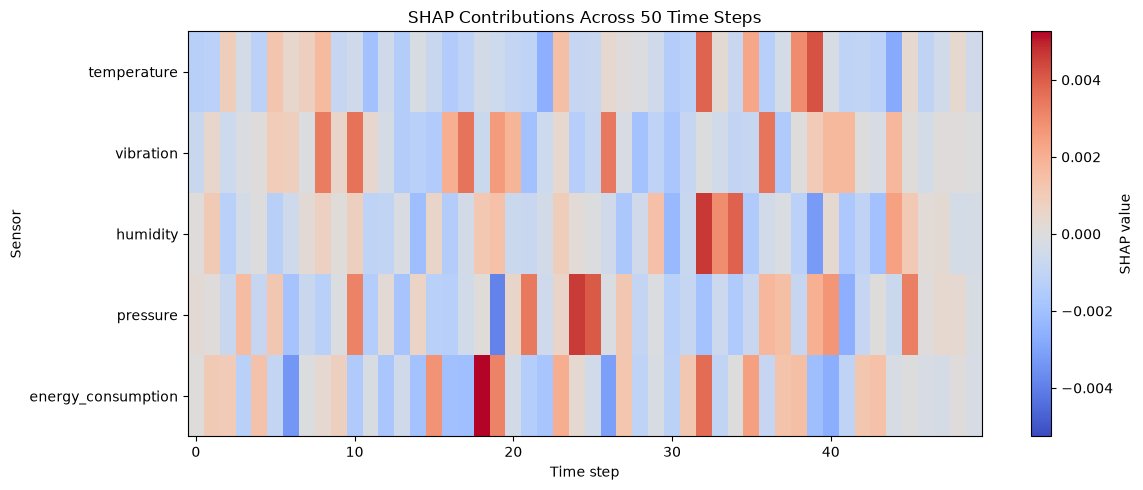


Explained sample actual label: 0
Explained sample predicted probability: 0.135271


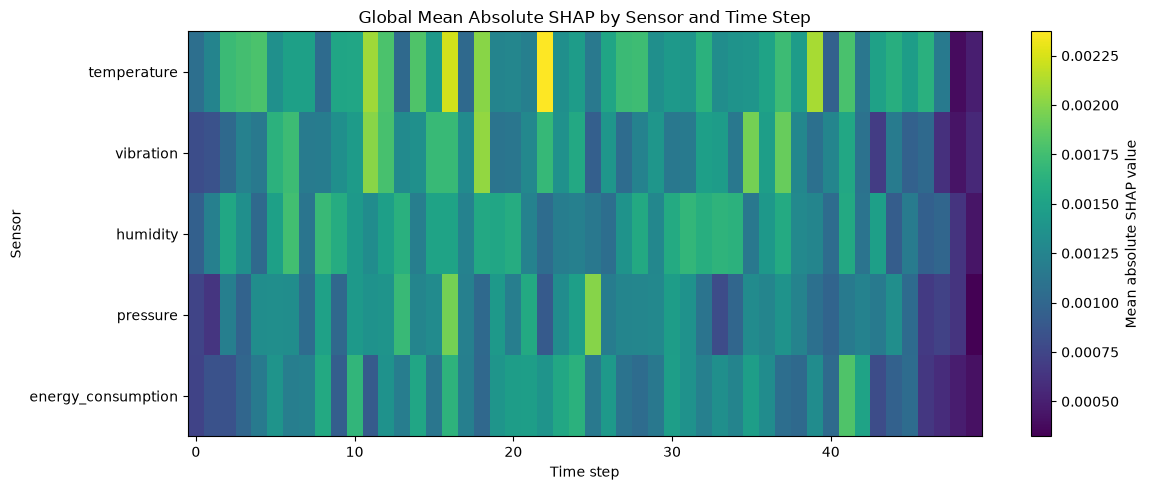


SHAP XAI ANALYSIS COMPLETED
Results saved in:
C:\Users\devin\Desktop\prob_project\dataset\shap_results

Files:
- confusion_matrix.png
- global_sensor_importance.csv
- global_sensor_importance.png
- global_shap_heatmap.png
- individual_shap_heatmap.png
- per_sample_shap_importance.csv
- shap_values.npy

Interpretation: positive SHAP values increase the model output relative to the background reference; negative values decrease it. Mean absolute SHAP values measure attribution magnitude, not causality.

Research caution: the scaler and sequence-building procedure above must match the original model's training pipeline before these metrics or explanations are treated as final.


In [15]:

# ==============================================================
# COMPLETE SHAP XAI PIPELINE
# Industrial Machine Fault Diagnosis
# Saved CNN model + SHAP explanations + evaluation + plots
# ==============================================================

import os
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import shap
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay,
    confusion_matrix
)

warnings.filterwarnings("ignore")
np.random.seed(42)

# --------------------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------------------

PROJECT_DIR = r"C:\Users\devin\Desktop\prob_project"
DATA_PATH = os.path.join(
    PROJECT_DIR, "dataset", "smart_manufacturing_data.csv"
)
MODEL_PATH = os.path.join(
    PROJECT_DIR, "dataset", "best_machine_cnn.keras"
)
OUTPUT_DIR = os.path.join(PROJECT_DIR, "dataset", "shap_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------------------------
# 2. LOAD MODEL AND DATASET
# --------------------------------------------------------------

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

if "model" not in globals():
    model = tf.keras.models.load_model(MODEL_PATH)

df = pd.read_csv(DATA_PATH)

features = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption"
]
target = "anomaly_flag"
TIME_STEPS = 50

print("=" * 65)
print("SHAP EXPLAINABLE AI - MACHINE FAULT DIAGNOSIS")
print("=" * 65)
print("Dataset shape:", df.shape)
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)
print("SHAP version:", shap.__version__)

if tuple(model.input_shape[1:]) != (50, 5):
    raise ValueError(
        f"Expected model input (None, 50, 5), got {model.input_shape}"
    )

required = features + [target, "timestamp", "machine_id"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# --------------------------------------------------------------
# 3. CLEAN AND ORDER DATA
# --------------------------------------------------------------

df["timestamp"] = pd.to_datetime(
    df["timestamp"], format="mixed",
    dayfirst=True, errors="coerce"
)

df = df.dropna(subset=required).copy()
df[target] = df[target].astype(int)

if not set(df[target].unique()).issubset({0, 1}):
    raise ValueError("anomaly_flag must contain binary labels 0 and 1.")

# Split chronologically by timestamp to reduce temporal leakage.
df = df.sort_values(["timestamp", "machine_id"]).reset_index(drop=True)
cutoff = df["timestamp"].quantile(0.80)

train_df = df[df["timestamp"] < cutoff].copy()
test_df = df[df["timestamp"] >= cutoff].copy()

if len(train_df) <= TIME_STEPS or len(test_df) == 0:
    raise ValueError("Insufficient rows for a chronological split.")

# Fit scaler on training rows only.
# IMPORTANT: this must match the scaler used during original training.
scaler = StandardScaler()
scaler.fit(train_df[features])

# Transform all rows, then build sequences separately per machine.
df["_partition"] = np.where(df["timestamp"] < cutoff, "train", "test")
df_scaled = scaler.transform(df[features])

# Map transformed rows back to their original dataframe positions.
scaled_df = df.copy()
scaled_df[features] = df_scaled

# Build test sequences using each machine's own history.
# Earlier rows may provide context, but test targets are after cutoff.
X_test_list, y_test_list = [], []

for machine_id, group in scaled_df.groupby("machine_id", sort=False):
    group = group.sort_values("timestamp")
    row_ids = group.index.to_numpy()
    vals = group[features].to_numpy(dtype=np.float32)
    labels = group[target].to_numpy(dtype=int)
    partitions = group["_partition"].to_numpy()

    for j in range(TIME_STEPS, len(group)):
        # The label timestamp must be in the test period.
        if partitions[j] != "test":
            continue

        X_test_list.append(vals[j - TIME_STEPS:j])
        y_test_list.append(labels[j])

X_test = np.asarray(X_test_list, dtype=np.float32)
y_test = np.asarray(y_test_list, dtype=int)

if len(X_test) == 0:
    raise ValueError("No test sequences created.")

print("\nTraining rows:", len(train_df))
print("Test rows:", len(test_df))
print("Test sequences:", X_test.shape)
print("Test labels:", y_test.shape)

# --------------------------------------------------------------
# 4. PREDICTIONS AND EVALUATION
# --------------------------------------------------------------

raw_predictions = np.asarray(model.predict(X_test, verbose=0))

if raw_predictions.ndim != 2 or raw_predictions.shape[1] != 1:
    raise ValueError(
        f"Expected one model output per sample; got {raw_predictions.shape}"
    )

y_prob = raw_predictions[:, 0]

if np.any(y_prob < 0) or np.any(y_prob > 1):
    raise ValueError(
        "Model outputs are not probabilities in [0,1]. "
        "Check the output activation before calculating metrics."
    )

THRESHOLD = 0.50
y_pred = (y_prob >= THRESHOLD).astype(int)

print("\n" + "=" * 65)
print("CNN EVALUATION")
print("=" * 65)
print("Threshold:", THRESHOLD)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
    print(
        "PR-AUC (average precision):",
        round(average_precision_score(y_test, y_prob), 4)
    )

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred, labels=[0, 1]),
    display_labels=["Normal", "Anomaly"]
).plot(values_format="d")

plt.title("CNN Anomaly Detection - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------------------
# 5. SELECT BACKGROUND AND EXPLANATION SAMPLES
# --------------------------------------------------------------

# Keep SHAP computational cost manageable.
rng = np.random.default_rng(42)
BACKGROUND_COUNT = min(20, len(X_test))
EXPLAIN_COUNT = min(30, len(X_test))

background_idx = rng.choice(
    len(X_test), size=BACKGROUND_COUNT, replace=False
)
explain_idx = rng.choice(
    len(X_test), size=EXPLAIN_COUNT, replace=False
)

background = X_test[background_idx]
X_explain = X_test[explain_idx]

print("\nSHAP background samples:", len(background))
print("Samples to explain:", len(X_explain))

# --------------------------------------------------------------
# 6. COMPUTE SHAP VALUES
# --------------------------------------------------------------

print("\nCalculating SHAP values. This may take some time...")

explainer = shap.GradientExplainer(model, background)
shap_raw = explainer.shap_values(X_explain)

# Handle SHAP versions returning a list for model outputs.
if isinstance(shap_raw, list):
    if len(shap_raw) != 1:
        raise ValueError(
            "This code expects a single-output model. "
            f"SHAP returned {len(shap_raw)} output arrays."
        )
    shap_raw = shap_raw[0]

shap_values = np.asarray(shap_raw)

# Common single-output format: (samples, 50, 5, 1)
if (
    shap_values.ndim == 4
    and shap_values.shape[-1] == 1
):
    shap_values = shap_values[..., 0]

print("SHAP values shape:", shap_values.shape)

if shap_values.shape != X_explain.shape:
    raise ValueError(
        "Unexpected SHAP output shape. "
        f"Expected {X_explain.shape}, got {shap_values.shape}. "
        "Check SHAP version/output format."
    )

# --------------------------------------------------------------
# 7. GLOBAL SENSOR IMPORTANCE
# --------------------------------------------------------------

# Average absolute attribution across explained samples and time.
global_importance = np.mean(np.abs(shap_values), axis=(0, 1))

ranking = sorted(
    zip(features, global_importance),
    key=lambda pair: pair[1],
    reverse=True
)

importance_df = pd.DataFrame(
    ranking, columns=["sensor", "mean_absolute_shap"]
)
importance_df.insert(0, "rank", np.arange(1, len(importance_df) + 1))

print("\n" + "=" * 65)
print("GLOBAL SHAP SENSOR IMPORTANCE")
print("=" * 65)
print(importance_df.to_string(index=False))

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_sensor_importance.csv"),
    index=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    importance_df["sensor"],
    importance_df["mean_absolute_shap"]
)
plt.xlabel("Sensor")
plt.ylabel("Mean absolute SHAP value")
plt.title("Global Sensor Importance - SHAP")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "global_sensor_importance.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------------------
# 8. SHAP HEATMAP FOR ONE EXAMPLE
# --------------------------------------------------------------

sample_position = 0
sample_shap = shap_values[sample_position]

limit = max(float(np.max(np.abs(sample_shap))), 1e-12)

plt.figure(figsize=(12, 5))
plt.imshow(
    sample_shap.T,
    aspect="auto",
    cmap="coolwarm",
    interpolation="nearest",
    vmin=-limit,
    vmax=limit
)
plt.yticks(range(len(features)), features)
plt.xlabel("Time step")
plt.ylabel("Sensor")
plt.title("SHAP Contributions Across 50 Time Steps")
plt.colorbar(label="SHAP value")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "individual_shap_heatmap.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

print("\nExplained sample actual label:", int(y_test[explain_idx[0]]))
print("Explained sample predicted probability:",
      round(float(y_prob[explain_idx[0]]), 6))

# --------------------------------------------------------------
# 9. GLOBAL TIME-STEP / SENSOR HEATMAP
# --------------------------------------------------------------

mean_time_sensor = np.mean(np.abs(shap_values), axis=0)

plt.figure(figsize=(12, 5))
plt.imshow(
    mean_time_sensor.T,
    aspect="auto",
    cmap="viridis",
    interpolation="nearest"
)
plt.yticks(range(len(features)), features)
plt.xlabel("Time step")
plt.ylabel("Sensor")
plt.title("Global Mean Absolute SHAP by Sensor and Time Step")
plt.colorbar(label="Mean absolute SHAP value")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "global_shap_heatmap.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------------------
# 10. SAVE PER-SAMPLE EXPLANATIONS
# --------------------------------------------------------------

# Mean absolute contribution for each sensor and explained sample.
per_sample_importance = np.mean(np.abs(shap_values), axis=1)

sample_results = pd.DataFrame(
    per_sample_importance, columns=features
)
sample_results.insert(0, "test_sample_index", explain_idx)
sample_results["actual_label"] = y_test[explain_idx]
sample_results["predicted_probability"] = y_prob[explain_idx]
sample_results["predicted_label"] = y_pred[explain_idx]

sample_results.to_csv(
    os.path.join(OUTPUT_DIR, "per_sample_shap_importance.csv"),
    index=False
)

# Save raw SHAP attributions for reproducibility.
np.save(
    os.path.join(OUTPUT_DIR, "shap_values.npy"),
    shap_values
)

print("\n" + "=" * 65)
print("SHAP XAI ANALYSIS COMPLETED")
print("=" * 65)
print("Results saved in:")
print(OUTPUT_DIR)
print("\nFiles:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print(
    "\nInterpretation: positive SHAP values increase the model output "
    "relative to the background reference; negative values decrease it. "
    "Mean absolute SHAP values measure attribution magnitude, not causality."
)
print(
    "\nResearch caution: the scaler and sequence-building procedure above "
    "must match the original model's training pipeline before these metrics "
    "or explanations are treated as final."
)
